In [1]:
import pandas as pd
import seaborn as sns

In [2]:
coeliac_sequences = pd.read_csv('../data/interim/sequences_coeliac_mutations.csv', index_col='id')
coeliac_sequences = coeliac_sequences[coeliac_sequences.index.map(lambda id_: 'original' in id_)]
coeliac_sequences['original'] = True

In [3]:
mutant_sequences = pd.read_csv('../data/interim/sequences_coeliac_peptide_mutants.csv', index_col='id')
mutant_sequences['original'] = False

In [4]:
sequences = pd.concat([coeliac_sequences, mutant_sequences])

In [5]:
coeliac_binding_scores = pd.read_csv(
    '../data/processed/af3_af3_tcrmodel2_coeliac_mutations_pae_aggregator_predictions.csv'
)
coeliac_binding_scores = coeliac_binding_scores[coeliac_binding_scores['name'].map(lambda name: 'original' in name)]

In [6]:
coeliac_mutant_binding_scores = pd.read_csv(
    '../data/processed/af3_af3_tcrmodel2_coeliac_peptide_mutants_pae_aggregator_predictions.csv'
)

In [7]:
binding_scores = pd.concat([coeliac_binding_scores, coeliac_mutant_binding_scores])

In [8]:
binding_scores['prediction'] = binding_scores[
    ['prediction_1', 'prediction_2', 'prediction_3', 'prediction_4', 'prediction_5']
].apply('median', axis=1)

In [9]:
binding_scores = binding_scores.merge(sequences, how='inner', left_on='name', right_index=True)

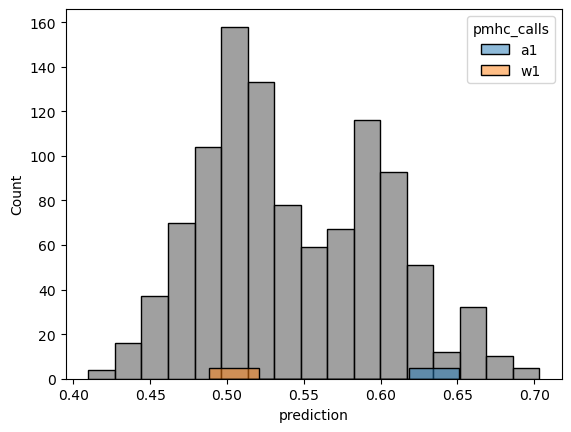

In [10]:
ax = sns.histplot(binding_scores.query('not original'), x='prediction', color='grey')
ax = sns.histplot(binding_scores.query('original'), x='prediction', hue='pmhc_calls', ax=ax)

In [11]:
a1_peptide = binding_scores.query("pmhc_calls == 'a1'")['peptide'].unique()[0]
w1_peptide = binding_scores.query("pmhc_calls == 'w1'")['peptide'].unique()[0]

In [12]:
def hamming_distance(string1: str, string2: str) -> int:
    count = 0
    for letter1, letter2 in zip(string1, string2, strict=True):
        if letter1 != letter2:
            count += 1

    return count

In [13]:
binding_scores['distance_from_a1'] = binding_scores['peptide'].map(
    lambda peptide, other=a1_peptide: hamming_distance(peptide, other)
)
binding_scores['distance_from_w1'] = binding_scores['peptide'].map(
    lambda peptide, other=w1_peptide: hamming_distance(peptide, other)
)

In [14]:
def classify_mutation(distance_from_a1: int, distance_from_w1: int) -> str:
    if distance_from_a1 < distance_from_w1:
        if distance_from_a1 == 0:
            return 'a1'

        return f'{distance_from_a1} edit distance to a1'

    if distance_from_w1 < distance_from_a1:
        if distance_from_w1 == 0:
            return 'w1'

        return f'{distance_from_w1} edit distance to w1'

    return f'{distance_from_a1} edit distance to either peptide'


binding_scores['mutant_class'] = binding_scores.apply(
    lambda row: classify_mutation(row.distance_from_a1, row.distance_from_w1), axis=1
)

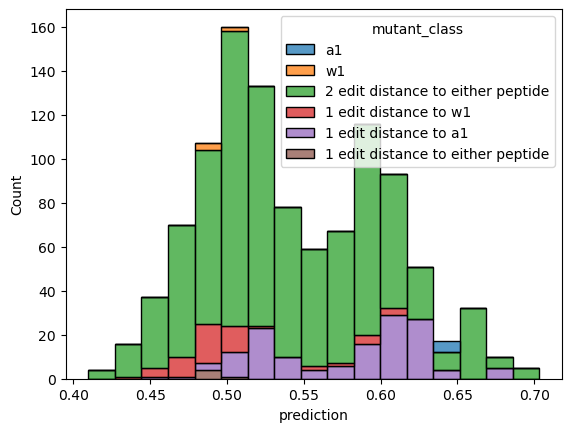

In [15]:
ax = sns.histplot(binding_scores, x='prediction', hue='mutant_class', multiple='stack')

In [16]:
print('Lowest binding potential mutant', binding_scores.loc[binding_scores['prediction'].idxmin(), 'peptide'])
print('Highest binding potential mutant', binding_scores.loc[binding_scores['prediction'].idxmax(), 'peptide'])

Lowest binding potential mutant QPFPQPECPSP
Highest binding potential mutant QPFPQPERPVP
